###Below:
It returns the image we want, a satellite map of IITGN, and its extent

In [19]:
import contextily as cx, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pyproj import Transformer

W, S, E, N = 72.665, 23.195, 72.705, 23.230   # west, south, east, north (degrees)
img, (x_min, x_max, y_min, y_max) = cx.bounds2img(
    W, S, E, N, ll=True, source=cx.providers.Esri.WorldImagery, zoom=16)
img = img[:, :, :3]                     # drop the transparency channel
H, Wpx = img.shape[:2]
print(img.shape, x_min, x_max, y_min, y_max)

(2048, 2048, 3) 8088872.081250491 8093764.051060743 2655116.614513883 2660008.5843241336


###Below:
Along x, the first pixel column corresponds to x_min and the last corresponds to x_max. But along y, the first pixel row (py=0) corresponds to y_max and the last row corresponds to y_min. That is why you say (y_max - (..)) in the formulas.

mx and my are in the mercator metres unit.

to_ll transforms mercator metres units to latitude and longitude. (px,py -> mx,my -> lat,lon)

to_merc transofmrs lat and lon to mercator meter units. in the latlon_to_pixel function we return the pixel values as you can see. (lat,lon -> mx,my -> px,py)

Haversine gives the true distance between two coordinates, in metres units.

In [20]:
mx_per_px = (x_max - x_min) / Wpx
my_per_px = (y_max - y_min) / H
to_ll   = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)
to_merc = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)

def pixel_to_latlon(px, py):
    mx = x_min + px * mx_per_px
    my = y_max - py * my_per_px
    lon, lat = to_ll.transform(mx, my)
    return lat, lon

def latlon_to_pixel(lat, lon):
    mx, my = to_merc.transform(lon, lat) #note how it takes lon then lat as arguments (common bug)
    return (mx - x_min) / mx_per_px, (y_max - my) / my_per_px

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6371000.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dp/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

###Below:

Error occurs due to 16-bit computer

round-trip error (m): 1.494668596507356e-09


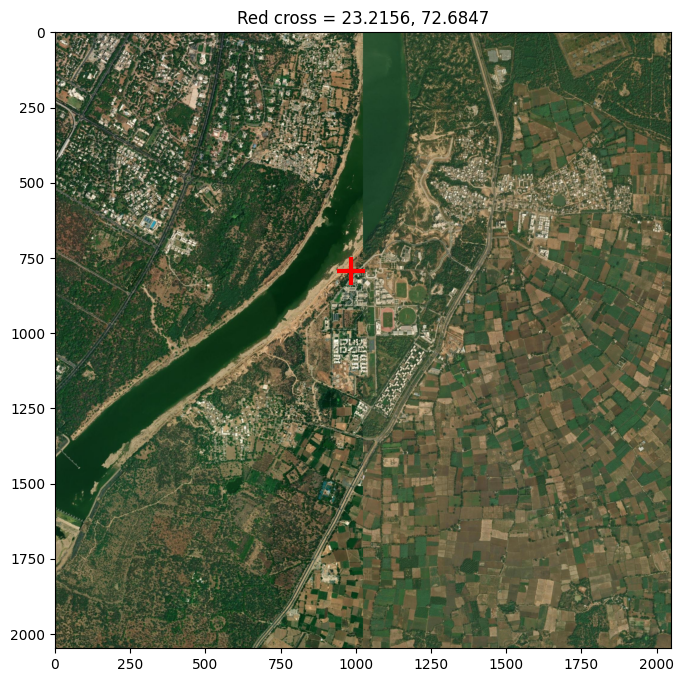

In [21]:
lat0, lon0 = 23.2156, 72.6847          # roughly IITGN campus
px, py = latlon_to_pixel(lat0, lon0)
print("round-trip error (m):", haversine_m(lat0, lon0, *pixel_to_latlon(px, py)))

plt.figure(figsize=(8, 8)); plt.imshow(img)
plt.plot(px, py, 'r+', markersize=20, mew=3); plt.title("Red cross = 23.2156, 72.6847")
plt.show()

###Below:
We are selecting step as half of tile. If we choose a smaller step then the size of the image that is between two non overlapping tiles that can fit will be small. If we choose a bigger step we will get too many tiles. So this is an optimal choice.


In [22]:
TILE, STEP = 512, 256          # tile size and stride, in pixels

rows = []
for y0 in range(0, H - TILE + 1, STEP):          # top edge of each tile, going down
    for x0 in range(0, Wpx - TILE + 1, STEP):    # left edge of each tile, going right
        north, west = pixel_to_latlon(x0, y0)                 # top-left corner
        south, east = pixel_to_latlon(x0 + TILE, y0 + TILE)   # bottom-right corner
        rows.append(dict(tile_id=len(rows), x0=x0, y0=y0,
                         north=north, south=south, west=west, east=east))

tiles = pd.DataFrame(rows)
print(len(tiles), "tiles")
tiles.head()

49 tiles


,tile_id,x0,y0,north,south,west,east
0,0,0,0,23.231251,23.221155,72.663574,72.674561
1,1,256,0,23.231251,23.221155,72.669067,72.680054
2,2,512,0,23.231251,23.221155,72.674561,72.685547
3,3,768,0,23.231251,23.221155,72.680054,72.691040
4,4,1024,0,23.231251,23.221155,72.685547,72.696533


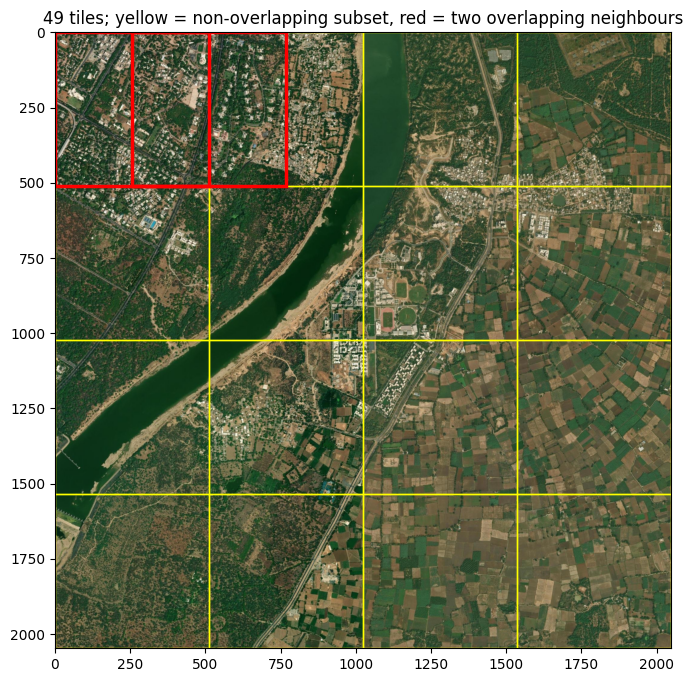

In [23]:
import matplotlib.patches as patches
fig, ax = plt.subplots(figsize=(8, 8)); ax.imshow(img)
grid = tiles[(tiles.x0 % (2*STEP) == 0) & (tiles.y0 % (2*STEP) == 0)]
for _, t in grid.iterrows():
    ax.add_patch(patches.Rectangle((t.x0, t.y0), TILE, TILE, fill=False, ec='yellow', lw=1))
for tid in [0, 1]:                                   # tile 0 and its neighbour, half a tile to the right
    t = tiles.loc[tid]
    ax.add_patch(patches.Rectangle((t.x0, t.y0), TILE, TILE, fill=False, ec='red', lw=2.5))
ax.set_title(f"{len(tiles)} tiles; yellow = non-overlapping subset, red = two overlapping neighbours")
plt.show()

###Below:


In [24]:
import cv2

CROP, OUT = 360, 256      # cut 360 px, rotate, keep the clean middle 256 px

def rotate_and_crop(patch, angle):        # stands in for: drone heading
    c = CROP / 2
    M = cv2.getRotationMatrix2D((c, c), angle, 1.0)
    rot = cv2.warpAffine(patch, M, (CROP, CROP))
    a = (CROP - OUT) // 2
    return rot[a:a + OUT, a:a + OUT]

def rescale(photo, scale):                # stands in for: altitude (scale < 1 = higher)
    size = int(round(OUT * scale))
    return cv2.resize(photo, (size, size), interpolation=cv2.INTER_AREA)

def change_lighting(photo, contrast, brightness):   # sun, season, exposure
    return cv2.convertScaleAbs(photo, alpha=contrast, beta=brightness)

def blur(photo, sigma):                   # motion blur, haze
    return cv2.GaussianBlur(photo, (0, 0), sigma) if sigma > 0 else photo

def thermal_like(photo, flip_frac, rng):
    """Crude infrared: grey, with a random fraction of the scene's brightness flipped, then smeared and noisy.
    flip_frac = 0 -> just grey and blurry; flip_frac = 1 -> fully inverted (the old version)."""
    g = cv2.cvtColor(photo, cv2.COLOR_RGB2GRAY).astype(np.float32)
    h, w = g.shape
    blobs = cv2.resize(rng.random((6, 6)).astype(np.float32), (w, h), interpolation=cv2.INTER_CUBIC)
    flip = blobs < np.quantile(blobs, flip_frac) if flip_frac > 0 else np.zeros_like(g, bool)
    g = np.where(flip, 255 - g, g)                       # some "materials" swap bright and dark, others don't
    g = cv2.GaussianBlur(g, (0, 0), 2.0)                  # thermal cameras are blurrier
    g = g + rng.normal(0, 6, g.shape)                     # and noisier
    g = np.clip(g, 0, 255).astype(np.uint8)
    return cv2.cvtColor(g, cv2.COLOR_GRAY2RGB)

In [25]:
N = 200
rng = np.random.default_rng(42)
half = CROP // 2

photos, rows = [], []
for qid in range(N):
    cx = int(rng.integers(half, Wpx - half))
    cy = int(rng.integers(half, H - half))
    true_lat, true_lon = pixel_to_latlon(cx, cy)

    angle = float(rng.uniform(0, 360))
    scale = float(rng.uniform(0.5, 1.8))                 # wider than before (was 0.6-1.5)
    sigma = float(rng.uniform(0, 3.0))                   # blurrier than before (was 0-1.5)
    kind = "IR" if qid % 2 == 1 else "EO"
    flip_frac = float(rng.uniform(0, 1)) if kind == "IR" else 0.0

    patch = img[cy - half:cy + half, cx - half:cx + half]
    photo = rotate_and_crop(patch, angle)
    photo = rescale(photo, scale)
    photo = change_lighting(photo, rng.uniform(0.6, 1.4), rng.uniform(-40, 40))
    photo = blur(photo, sigma)
    if kind == "IR":
        photo = thermal_like(photo, flip_frac, rng)

    photos.append(photo)
    rows.append(dict(qid=qid, cx=cx, cy=cy, true_lat=true_lat, true_lon=true_lon,
                     angle=angle, scale=scale, blur=sigma, kind=kind, flip_frac=flip_frac))

queries = pd.DataFrame(rows)
print(queries.kind.value_counts())
queries.head()

kind
EO    100
IR    100
Name: count, dtype: int64


,qid,cx,cy,true_lat,true_lon,angle,scale,blur,kind,flip_frac
0,0,330,1486,23.201947,72.670655,157.996238,1.616177,2.092104,EO,0.000000
1,1,1421,1464,23.202381,72.694066,282.983150,0.666548,1.351158,IR,0.370798
2,2,1122,197,23.227366,72.687650,3.384868,1.785713,1.582280,EO,0.000000
3,3,220,1548,23.200724,72.668295,325.783844,1.181840,1.115142,IR,0.702357
4,4,1777,1586,23.199975,72.701705,46.405833,0.668334,2.151212,EO,0.000000


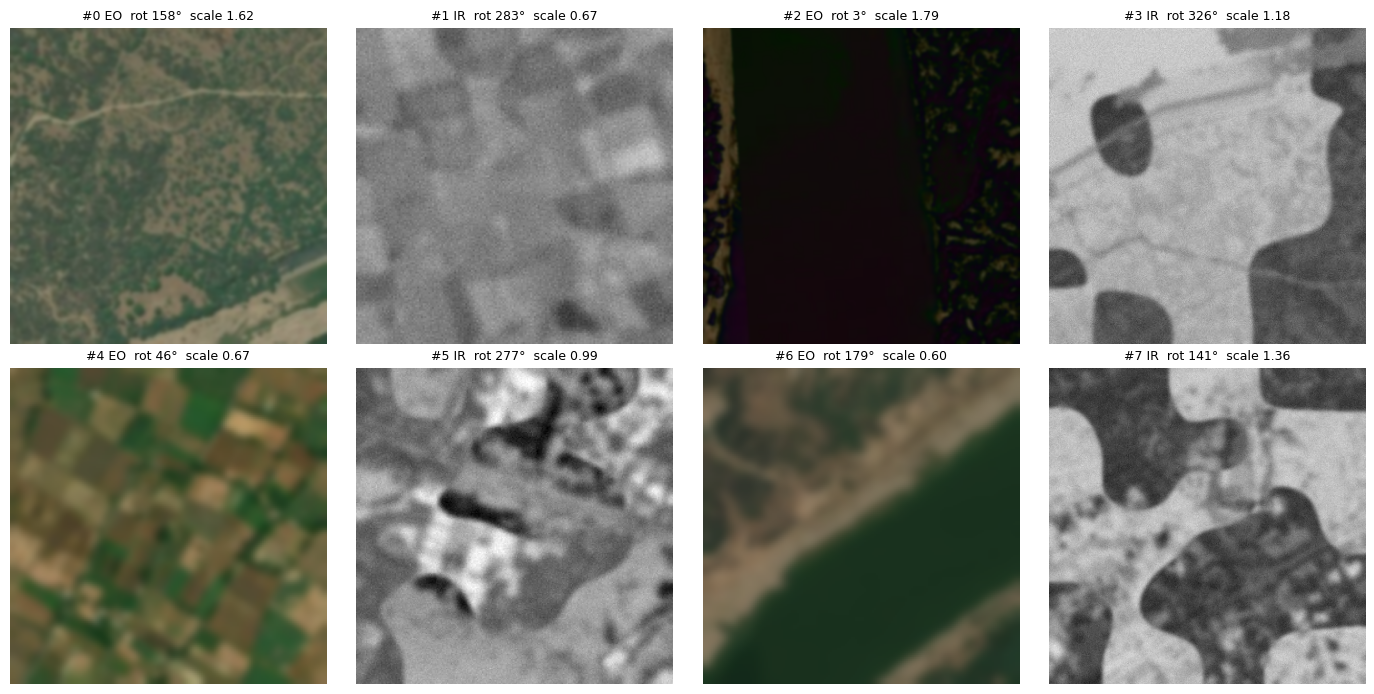

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, q in zip(axes.flat, range(8)):
    r = queries.loc[q]
    ax.imshow(photos[q]); ax.axis('off')
    ax.set_title(f"#{q} {r.kind}  rot {r.angle:.0f}°  scale {r.scale:.2f}", fontsize=9)
plt.tight_layout()
plt.show()

###Below:
We are finding out the keypoints for every tile before the loop itself as the tiles stay unchanged right throughout the process.

Next, for a given photo and a given tile,

###Keypoint:
a spot in the image that you can find again

###Descriptor (or fingerprint):
a list of numbers describing what the area around a keypoint looks like

###Basically, the match_to_tile function:
We first find the two most similar keypoints in the tile for every keypoint in the image. We only keep a pair if the first is clearly better than the second, else we remove it.
Now if we have more than 4 pairs we do the following:

RANSAC basically takes 4 random pairs out of all the pairs we have, it computes the mapping using those 4. If the photo lands in the tile, then pair 1 will have image's coordinate close to tile's coordinate, and pair 2 will have similar, and pair 3 and so on. Using a threshold we will count how many pairs have close enough coordinate.
We run this loop many times. In the end we pick the round where highest number of pairs which have close enough coordinate are there.

Now we take take the winning guess' pairs(inliers) and refit the mapping to it.

In [27]:
import time
sift = cv2.SIFT_create()
bf = cv2.BFMatcher(cv2.NORM_L2)

# Map side, done once ("prepared ahead of time"): keypoints for every tile
tile_feats = []
t0 = time.time()
for t in tiles.itertuples():
    tile_img = img[t.y0:t.y0 + TILE, t.x0:t.x0 + TILE]
    kp, des = sift.detectAndCompute(cv2.cvtColor(tile_img, cv2.COLOR_RGB2GRAY), None)
    tile_feats.append((kp, des))
print(f"tile keypoints: {time.time() - t0:.1f} s for {len(tiles)} tiles")

def match_to_tile(kp_q, des_q, kp_t, des_t, ratio=0.75):
    """Return (homography, inlier count) for one photo against one tile, or (None, 0)."""
    if des_q is None or des_t is None or len(des_t) < 2:
        return None, 0
    pairs = bf.knnMatch(des_q, des_t, k=2)                       # best 2 candidates per photo keypoint
    good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    if len(good) < 4:                                             # a homography needs at least 4 pairs
        return None, 0
    src = np.float32([kp_q[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_t[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    Hmat, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    if Hmat is None:
        return None, 0
    return Hmat, int(mask.sum())

tile keypoints: 8.6 s for 49 tiles


In [28]:
def localise(photo):
    """Find the photo on the map. Returns (lat, lon, inliers, tile_id); lat/lon are NaN if nothing matched."""
    kp_q, des_q = sift.detectAndCompute(cv2.cvtColor(photo, cv2.COLOR_RGB2GRAY), None)
    best_H, best_n, best_tile = None, 0, -1
    for tid, (kp_t, des_t) in enumerate(tile_feats):
        Hmat, n = match_to_tile(kp_q, des_q, kp_t, des_t)
        if n > best_n:
            best_H, best_n, best_tile = Hmat, n, tid
    if best_H is None:
        return np.nan, np.nan, 0, -1
    h, w = photo.shape[:2]
    centre = np.float32([[[w / 2, h / 2]]])
    tx, ty = cv2.perspectiveTransform(centre, best_H)[0, 0]      # photo centre -> pixel inside the tile
    t = tiles.loc[best_tile]
    lat, lon = pixel_to_latlon(t.x0 + tx, t.y0 + ty)              # tile pixel -> map pixel -> lat/lon
    return lat, lon, best_n, best_tile

In [29]:
results = []
t0 = time.time()
for qid, photo in enumerate(photos):
    lat, lon, n, tid = localise(photo)
    results.append(dict(qid=qid, pred_lat=lat, pred_lon=lon, inliers=n, best_tile=tid))
    if qid % 20 == 0:
        print(f"{qid}/{len(photos)} done, {time.time() - t0:.0f} s")
print(f"total {time.time() - t0:.0f} s, {1000 * (time.time() - t0) / len(photos):.0f} ms per photo")

res = queries.merge(pd.DataFrame(results), on="qid")
res.head()

0/200 done, 0 s
20/200 done, 28 s
40/200 done, 54 s
60/200 done, 92 s
80/200 done, 115 s
100/200 done, 132 s
120/200 done, 150 s
140/200 done, 189 s
160/200 done, 212 s
180/200 done, 247 s
total 290 s, 1452 ms per photo


,qid,cx,cy,true_lat,true_lon,angle,scale,blur,kind,flip_frac,pred_lat,pred_lon,inliers,best_tile
0,0,330,1486,23.201947,72.670655,157.996238,1.616177,2.092104,EO,0.000000,23.201938,72.670668,35,35
1,1,1421,1464,23.202381,72.694066,282.983150,0.666548,1.351158,IR,0.370798,NaN,NaN,0,-1
2,2,1122,197,23.227366,72.687650,3.384868,1.785713,1.582280,EO,0.000000,23.227368,72.687646,20,3
3,3,220,1548,23.200724,72.668295,325.783844,1.181840,1.115142,IR,0.702357,23.213142,72.677234,4,15
4,4,1777,1586,23.199975,72.701705,46.405833,0.668334,2.151212,EO,0.000000,23.199977,72.701710,21,41


In [30]:
res.to_csv("results_step3.csv", index=False)
# after a restart: res = pd.read_csv("results_step3.csv")   (then re-run cells 1–5 for the map/functions)

In [31]:
def ps_score(err_m):
    """The PS's example scoring for an answered photo."""
    if np.isnan(err_m):  return -4          # answered but nothing usable -> counts as wrong
    if err_m < 100:      return 8
    if err_m < 250:      return 4
    if err_m < 500:      return 2
    return -4

res["err_m"] = haversine_m(res.true_lat, res.true_lon, res.pred_lat, res.pred_lon)
res["score_if_answered"] = res.err_m.apply(ps_score)
res[["qid", "kind", "inliers", "err_m", "score_if_answered"]].head(10)

,qid,kind,inliers,err_m,score_if_answered
0,0,EO,35,1.619262,8
1,1,IR,0,NaN,-4
2,2,EO,20,0.398816,8
3,3,IR,4,1655.687486,-4
4,4,EO,21,0.605794,8
5,5,IR,0,NaN,-4
6,6,EO,0,NaN,-4
7,7,IR,8,7.293372,8
8,8,EO,77,1.524134,8
9,9,IR,73,1.659010,8


In [32]:
res["scale_band"] = pd.cut(res.scale, [0, 0.8, 1.2, 2], labels=["small (high alt)", "~1", "large (low alt)"])

def summary(g):
    return pd.Series({
        "photos":         len(g),
        "median_err_m":   g.err_m.median(),
        "under_100m_%":   100 * (g.err_m < 100).mean(),
        "under_500m_%":   100 * (g.err_m < 500).mean(),
        "median_inliers": g.inliers.median(),
        "score_answer_all": g.score_if_answered.sum(),
    })

res["flip_band"] = pd.cut(res.flip_frac, [0, 0.33, 0.66, 1], labels=["light", "medium", "heavy"])
ir = res[res.kind == "IR"]

table = pd.concat({
    "all": summary(res),
    "EO":  summary(res[res.kind == "EO"]),
    "IR":  summary(ir),
    **{f"scale {b}": summary(res[res.scale_band == b]) for b in res.scale_band.cat.categories},
    **{f"IR flip {b}": summary(ir[ir.flip_band == b]) for b in res.flip_band.cat.categories},
}, axis=1).T.round(1)
table

,photos,median_err_m,under_100m_%,under_500m_%,median_inliers,score_answer_all
all,200.0,1.5,66.0,68.5,20.5,820.0
EO,100.0,1.3,93.0,93.0,74.5,716.0
IR,100.0,2.3,39.0,44.0,4.0,104.0
scale small (high alt),48.0,1.0,43.8,45.8,0.0,66.0
scale ~1,59.0,1.4,54.2,57.6,12.0,164.0
scale large (low alt),93.0,1.6,84.9,87.1,36.0,590.0
IR flip light,35.0,1.6,71.4,74.3,21.0,166.0
IR flip medium,32.0,7.3,34.4,43.8,4.0,26.0
IR flip heavy,33.0,1650.6,9.1,12.1,0.0,-88.0


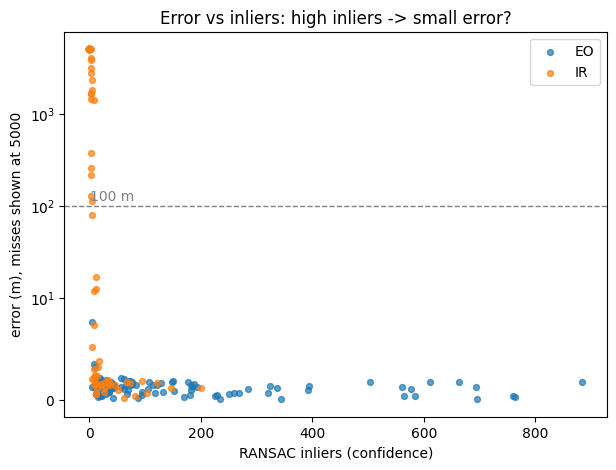

In [37]:
fig, ax = plt.subplots(figsize=(7, 5))
for kind, colour in [("EO", "tab:blue"), ("IR", "tab:orange")]:
    g = res[res.kind == kind]
    ax.scatter(g.inliers, g.err_m.fillna(5000).clip(upper=5000), s=18, alpha=0.7, label=kind, c=colour)
ax.set_yscale("symlog", linthresh=10)
ax.axhline(100, ls="--", c="grey", lw=1); ax.text(1, 115, "100 m", color="grey")
ax.set_xlabel("RANSAC inliers (confidence)"); ax.set_ylabel("error (m), misses shown at 5000")
ax.set_title("Error vs inliers: high inliers -> small error?")
plt.legend()
plt.savefig("error_vs_inliers.png", dpi=150, bbox_inches="tight")
plt.show()

In [34]:
res.to_csv("results_v2.csv", index=False)

In [35]:
# 1. split photos into two halves at random (fixed seed): tune on one, report on the other
rng = np.random.default_rng(0)
is_val = rng.permutation(len(res)) < len(res) // 2
val, test = res[is_val], res[~is_val]

# 2. score of a rule "answer only if inliers >= T" (no match scores 0)
def score_at(df, T):
    answered = df.inliers >= T
    return df.score_if_answered[answered].sum(), answered.mean()

# 3. try every T from 0 to 100 on the validation half only, keep the best
Ts = np.arange(0, 101)
sweep = pd.DataFrame([(T, *score_at(val, T)) for T in Ts], columns=["T", "score", "answer_rate"])
best_T = int(sweep.loc[sweep.score.idxmax(), "T"])

# 4. report: answer-everything vs our rule, on both halves
for name, df in [("validation", val), ("held-out", test)]:
    s_all, _ = score_at(df, 0)
    s_T, rate = score_at(df, best_T)
    print(f"{name:10s}  answer-all score {s_all:5d}   with T={best_T}: {s_T:5d}  (answers {100*rate:.0f}%)")

validation  answer-all score   382   with T=6:   504  (answers 66%)
held-out    answer-all score   438   with T=6:   524  (answers 66%)


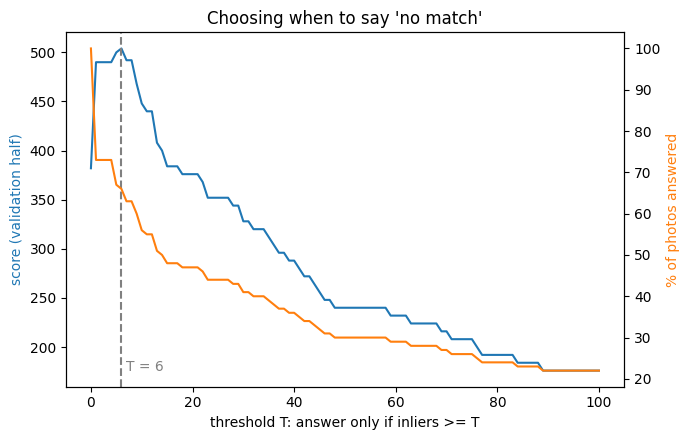

In [38]:
fig, ax1 = plt.subplots(figsize=(7, 4.5))
ax1.plot(sweep["T"], sweep.score, c="tab:blue"); ax1.set_ylabel("score (validation half)", color="tab:blue")
ax1.axvline(best_T, ls="--", c="grey"); ax1.text(best_T + 1, sweep.score.min(), f"T = {best_T}", color="grey")
ax2 = ax1.twinx(); ax2.plot(sweep["T"], 100 * sweep.answer_rate, c="tab:orange")
ax2.set_ylabel("% of photos answered", color="tab:orange")
ax1.set_xlabel("threshold T: answer only if inliers >= T")
ax1.set_title("Choosing when to say 'no match'")
plt.tight_layout()
plt.savefig("score_vs_threshold.png", dpi=150, bbox_inches="tight")
plt.show()